# N-gram Language Models: Unsmoothed, Add-1, Add-k, Interpolated, Kneser-Ney

This notebook builds unigram, bigram, trigram, and quadgram (N=1,2,3,4) language models
over a 1,000,000-sentence corpus, evaluates five smoothing strategies, and compares
perplexities on a held-out test set.

**Important — about the corpus.** The assignment says *"use the same corpus ... that you
developed in the previous assignment."* This notebook doesn't have access to that file, so
it gives you two options (see the next section):

- **Option A (recommended):** point `CORPUS_PATH` at your own corpus from the previous
  assignment (one sentence per line, or a `.csv`/`.txt` you already have as a Kaggle
  Dataset input). This is what you should use for the real submission.
- **Option B (fallback):** if no path is given, the notebook auto-builds a demo corpus of
  exactly 1,000,000 sentences from NLTK's built-in corpora (Brown, Gutenberg, Reuters,
  Webtext, Inaugural), shuffled and repeated as needed to reach the target size, so the
  whole pipeline still runs end-to-end. This is only a stand-in — swap in your real corpus
  for the actual assignment results.

Everything downstream (splits, vocab, models, smoothing, perplexity) works identically
either way.


## 0. Setup

In [1]:
import re
import math
import random
import time
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
for pkg in ["punkt", "punkt_tab", "brown", "gutenberg", "reuters", "webtext", "inaugural"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception as e:
        print(f"Could not download {pkg}: {e}")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


## 1. Load the corpus (1,000,000 sentences)

Set `CORPUS_PATH` below if you have your own corpus (recommended — this should be the
same corpus you built in the previous assignment). Expected format: **one sentence per
line, plain text**. If `CORPUS_PATH` is `None`, or the file isn't found, a demo corpus is
auto-generated from NLTK so the notebook still runs.

In [2]:
# ----- CONFIG: point this at your own corpus if you have it -----
CORPUS_PATH = None   # e.g. "/kaggle/input/my-corpus/corpus.txt"
TARGET_SENTENCES = 1_000_000
# ------------------------------------------------------------------

def load_own_corpus(path):
    sentences = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if line:
                sentences.append(line)
    return sentences


def build_demo_corpus(target=TARGET_SENTENCES, seed=RANDOM_SEED):
    """Fallback corpus: pools several NLTK corpora into sentences, then shuffles /
    repeats until it reaches `target` sentences. This is ONLY a stand-in for the real
    corpus from the previous assignment."""
    from nltk.corpus import brown, gutenberg, reuters, webtext, inaugural

    pool = []
    for corpus in (brown, gutenberg, reuters, webtext, inaugural):
        for sent_tokens in corpus.sents():
            s = " ".join(sent_tokens).strip()
            if len(s.split()) >= 2:
                pool.append(s)

    rng = random.Random(seed)
    rng.shuffle(pool)
    print(f"Base pool of unique sentences pulled from NLTK corpora: {len(pool):,}")

    all_sents = []
    while len(all_sents) < target:
        rng.shuffle(pool)
        all_sents.extend(pool)
    all_sents = all_sents[:target]
    rng.shuffle(all_sents)
    return all_sents


t0 = time.time()
if CORPUS_PATH is not None:
    try:
        sentences = load_own_corpus(CORPUS_PATH)
        print(f"Loaded {len(sentences):,} sentences from {CORPUS_PATH}")
    except FileNotFoundError:
        print(f"CORPUS_PATH not found ({CORPUS_PATH}); falling back to the demo corpus.")
        sentences = build_demo_corpus()
else:
    print("No CORPUS_PATH given; building the demo corpus (fallback).")
    sentences = build_demo_corpus()

print(f"Total sentences: {len(sentences):,}  (built in {time.time()-t0:.1f}s)")


No CORPUS_PATH given; building the demo corpus (fallback).
Base pool of unique sentences pulled from NLTK corpora: 240,992
Total sentences: 1,000,000  (built in 15.4s)


## 2. Train / development / test splits

Same corpus, same splits reused throughout: **80% train / 10% dev / 10% test.**
Change the ratios here if your previous assignment used different ones.

In [3]:
TRAIN_FRAC, DEV_FRAC, TEST_FRAC = 0.8, 0.1, 0.1
assert abs(TRAIN_FRAC + DEV_FRAC + TEST_FRAC - 1.0) < 1e-9

rng = random.Random(RANDOM_SEED)
shuffled = sentences[:]
rng.shuffle(shuffled)

n = len(shuffled)
n_train = int(n * TRAIN_FRAC)
n_dev = int(n * DEV_FRAC)

train_sents = shuffled[:n_train]
dev_sents = shuffled[n_train:n_train + n_dev]
test_sents = shuffled[n_train + n_dev:]

print(f"Train: {len(train_sents):,}")
print(f"Dev:   {len(dev_sents):,}")
print(f"Test:  {len(test_sents):,}")


Train: 800,000
Dev:   100,000
Test:  100,000


## 3. Preprocessing: tokenization, vocabulary, and `<unk>`

Tokens are lowercased and non-alphanumeric characters stripped. Any train-set word
occurring fewer than `MIN_COUNT` times (and any word never seen in train) is mapped to
`<unk>`, so dev/test can contain out-of-vocabulary words without breaking the models.

In [4]:
MIN_COUNT = 2  # words rarer than this in train become <unk>
BOS, EOS, UNK = "<s>", "</s>", "<unk>"

_token_re = re.compile(r"[a-z0-9']+")

def tokenize(sentence):
    return _token_re.findall(sentence.lower())


print("Counting word frequencies in train...")
word_counts = Counter()
for s in train_sents:
    word_counts.update(tokenize(s))

vocab = {w for w, c in word_counts.items() if c >= MIN_COUNT}
vocab.add(UNK)
V = len(vocab)
print(f"Vocabulary size (incl. <unk>): {V:,}")


def to_unk(tokens):
    return [t if t in vocab else UNK for t in tokens]


Counting word frequencies in train...
Vocabulary size (incl. <unk>): 85,708


## 4. N-gram counting

For an order-`n` model, each sentence is padded with `n-1` `<s>` tokens at the start and
one `</s>` at the end. We count every n-gram and its (n-1)-gram context. Building order 4
also gives us orders 1–3 "for free" via the prefix counts, but for clarity each order is
built independently below (bigram/trigram/quadgram share utility code).

In [5]:
class NgramCounts:
    """Counts for a single order n, plus the (n-1) context counts needed for MLE."""
    def __init__(self, n):
        self.n = n
        self.ngram_counts = defaultdict(int)
        self.context_counts = defaultdict(int)
        self.total_tokens = 0  # only meaningful for n == 1

    def pad(self, tokens):
        return [BOS] * (self.n - 1) + tokens + [EOS]

    def add_sentence(self, tokens):
        padded = self.pad(tokens)
        for i in range(self.n - 1, len(padded)):
            ngram = tuple(padded[i - self.n + 1:i + 1])
            context = ngram[:-1]
            self.ngram_counts[ngram] += 1
            self.context_counts[context] += 1
            if self.n == 1:
                self.total_tokens += 1


def build_ngram_model(n, sentences_list):
    model = NgramCounts(n)
    for s in sentences_list:
        tokens = to_unk(tokenize(s))
        model.add_sentence(tokens)
    return model


print("Building n-gram counts for n = 1, 2, 3, 4 on train (this may take a few minutes)...")
models = {}
for n in (1, 2, 3, 4):
    t0 = time.time()
    models[n] = build_ngram_model(n, train_sents)
    print(f"  n={n}: {len(models[n].ngram_counts):,} distinct n-grams "
          f"({time.time()-t0:.1f}s)")


Building n-gram counts for n = 1, 2, 3, 4 on train (this may take a few minutes)...
  n=1: 85,709 distinct n-grams (22.1s)
  n=2: 1,329,099 distinct n-grams (33.7s)
  n=3: 3,232,279 distinct n-grams (40.1s)
  n=4: 4,277,012 distinct n-grams (41.1s)


## 5. Perplexity helper

Perplexity is computed as `2 ** (-avg log2 prob per token)` over the (padded) evaluation
sentences. Any `p <= 0` is floored to a tiny epsilon so `log2` doesn't blow up (this only
matters for the *unsmoothed* model, which assigns true zero probability to unseen
n-grams).

Evaluating the full 100,000-sentence test set for every model/smoothing combination is
slow in pure Python; `EVAL_SAMPLE_SIZE` lets you evaluate on a random subsample for speed.
Set it to `None` to use the full test set.

In [6]:
EVAL_SAMPLE_SIZE = 20_000   # set to None to evaluate on the FULL test set (slower)
EPS = 1e-12

def maybe_sample(sents, k, seed=RANDOM_SEED):
    if k is None or k >= len(sents):
        return sents
    return random.Random(seed).sample(sents, k)

eval_test_sents = maybe_sample(test_sents, EVAL_SAMPLE_SIZE)
eval_dev_sents = maybe_sample(dev_sents, EVAL_SAMPLE_SIZE)
print(f"Evaluating on {len(eval_test_sents):,} test sentences "
      f"and {len(eval_dev_sents):,} dev sentences.")


def perplexity(prob_fn, n, sents):
    total_log_prob = 0.0
    total_tokens = 0
    padder = NgramCounts(n)
    for s in sents:
        tokens = to_unk(tokenize(s))
        padded = padder.pad(tokens)
        for i in range(n - 1, len(padded)):
            ngram = tuple(padded[i - n + 1:i + 1])
            p = prob_fn(ngram)
            if p <= 0:
                p = EPS
            total_log_prob += math.log2(p)
            total_tokens += 1
    return 2 ** (-total_log_prob / total_tokens)


Evaluating on 20,000 test sentences and 20,000 dev sentences.


## 6. Smoothing method 1 — Unsmoothed (raw MLE counts)

$$P(w_n \mid w_1,\dots,w_{n-1}) = \dfrac{C(w_1,\dots,w_n)}{C(w_1,\dots,w_{n-1})}$$

Unseen n-grams get probability 0 (perplexity will be `inf`, or very large once floored by
`EPS` — that's expected and is exactly the problem smoothing exists to fix).

In [7]:
def make_unsmoothed(model):
    def prob(ngram):
        context = ngram[:-1]
        c_ngram = model.ngram_counts.get(ngram, 0)
        if model.n == 1:
            c_context = model.total_tokens
        else:
            c_context = model.context_counts.get(context, 0)
        if c_context == 0:
            return 0.0
        return c_ngram / c_context
    return prob


## 7. Smoothing method 2 — Add-1 / Laplace

$$P_{Laplace}(w_n \mid w_1,\dots,w_{n-1}) = \dfrac{C(w_1,\dots,w_n) + 1}{C(w_1,\dots,w_{n-1}) + V}$$

In [8]:
def make_laplace(model):
    def prob(ngram):
        context = ngram[:-1]
        c_ngram = model.ngram_counts.get(ngram, 0)
        c_context = model.total_tokens if model.n == 1 else model.context_counts.get(context, 0)
        return (c_ngram + 1) / (c_context + V)
    return prob


## 8. Smoothing method 3 — Add-k (0 < k < 1)

$$P_{k}(w_n \mid w_1,\dots,w_{n-1}) = \dfrac{C(w_1,\dots,w_n) + k}{C(w_1,\dots,w_{n-1}) + kV}$$

`k` is chosen per order by a small grid search that minimizes **dev-set** perplexity.

In [9]:
def make_addk(model, k):
    def prob(ngram):
        context = ngram[:-1]
        c_ngram = model.ngram_counts.get(ngram, 0)
        c_context = model.total_tokens if model.n == 1 else model.context_counts.get(context, 0)
        return (c_ngram + k) / (c_context + k * V)
    return prob


K_GRID = [0.01, 0.05, 0.1, 0.2, 0.5, 0.9]

best_k = {}
for n in (1, 2, 3, 4):
    scores = []
    for k in K_GRID:
        pp = perplexity(make_addk(models[n], k), n, eval_dev_sents)
        scores.append((k, pp))
    scores.sort(key=lambda x: x[1])
    best_k[n] = scores[0][0]
    print(f"n={n}: dev perplexities by k -> " +
          ", ".join(f"k={k}: {pp:.1f}" for k, pp in scores) +
          f"   [best k = {best_k[n]}]")


n=1: dev perplexities by k -> k=0.9: 1319.6, k=0.5: 1319.6, k=0.2: 1319.7, k=0.1: 1319.8, k=0.05: 1319.8, k=0.01: 1319.8   [best k = 0.9]
n=2: dev perplexities by k -> k=0.01: 213.1, k=0.05: 336.4, k=0.1: 439.6, k=0.2: 600.5, k=0.5: 966.9, k=0.9: 1356.0   [best k = 0.01]
n=3: dev perplexities by k -> k=0.01: 190.8, k=0.05: 643.0, k=0.1: 1134.3, k=0.2: 2025.7, k=0.5: 4333.9, k=0.9: 6902.9   [best k = 0.01]
n=4: dev perplexities by k -> k=0.01: 254.9, k=0.05: 1076.9, k=0.1: 2012.9, k=0.2: 3728.5, k=0.5: 8106.7, k=0.9: 12783.6   [best k = 0.01]


## 9. Smoothing method 4 — Interpolated (Jelinek-Mercer)

For unigrams, exactly as specified:

$$P_{smooth}(w_i) = \lambda P(w_i) + (1-\lambda)\dfrac{1}{V}$$

For n > 1, each order is recursively interpolated with the lower-order interpolated
model:

$$P_{interp}(w_n \mid w_1,\dots,w_{n-1}) = \lambda_n \, P_{MLE}(w_n \mid w_1,\dots,w_{n-1}) + (1-\lambda_n)\, P_{interp}(w_n \mid w_2,\dots,w_{n-1})$$

with the n=1 base case above. Each $\lambda_n$ is tuned on the **dev set** by grid
search.

In [10]:
LAMBDA_GRID = [0.1, 0.3, 0.5, 0.7, 0.9]

def unigram_mle(model_1, w):
    c = model_1.ngram_counts.get((w,), 0)
    return c / model_1.total_tokens if model_1.total_tokens else 0.0

def make_unigram_interp(model_1, lam):
    def prob(ngram):
        w = ngram[-1]
        return lam * unigram_mle(model_1, w) + (1 - lam) * (1.0 / V)
    return prob


def make_interp(n, lambdas):
    """lambdas: dict order -> lambda for orders 2..n. Order 1 uses lambdas[1]."""
    def prob_n(order, ngram):
        if order == 1:
            return make_unigram_interp(models[1], lambdas[1])(ngram)
        model = models[order]
        context = ngram[:-1]
        c_ngram = model.ngram_counts.get(ngram, 0)
        c_context = model.context_counts.get(context, 0)
        mle = (c_ngram / c_context) if c_context else 0.0
        lower = prob_n(order - 1, ngram[1:])
        lam = lambdas[order]
        return lam * mle + (1 - lam) * lower

    def prob(ngram):
        return prob_n(n, ngram)
    return prob


# Tune lambda_1 for the unigram model on dev
scores = [(lam, perplexity(make_unigram_interp(models[1], lam), 1, eval_dev_sents))
          for lam in LAMBDA_GRID]
scores.sort(key=lambda x: x[1])
best_lambda = {1: scores[0][0]}
print(f"n=1: dev perplexities by lambda -> " +
      ", ".join(f"lam={l}: {pp:.1f}" for l, pp in scores) +
      f"   [best lambda = {best_lambda[1]}]")

# Tune lambda_n for n=2,3,4, one order at a time, holding lower-order lambdas fixed
for n in (2, 3, 4):
    scores = []
    for lam in LAMBDA_GRID:
        trial_lambdas = dict(best_lambda)
        trial_lambdas[n] = lam
        pp = perplexity(make_interp(n, trial_lambdas), n, eval_dev_sents)
        scores.append((lam, pp))
    scores.sort(key=lambda x: x[1])
    best_lambda[n] = scores[0][0]
    print(f"n={n}: dev perplexities by lambda -> " +
          ", ".join(f"lam={l}: {pp:.1f}" for l, pp in scores) +
          f"   [best lambda = {best_lambda[n]}]")

print("Chosen lambdas:", best_lambda)


n=1: dev perplexities by lambda -> lam=0.9: 1378.7, lam=0.7: 1631.7, lam=0.5: 2091.1, lam=0.3: 3067.1, lam=0.1: 6753.2   [best lambda = 0.9]
n=2: dev perplexities by lambda -> lam=0.9: 141.9, lam=0.7: 166.3, lam=0.5: 205.8, lam=0.3: 279.4, lam=0.1: 484.6   [best lambda = 0.9]
n=3: dev perplexities by lambda -> lam=0.9: 15.1, lam=0.7: 17.6, lam=0.5: 21.5, lam=0.3: 28.6, lam=0.1: 48.1   [best lambda = 0.9]
n=4: dev perplexities by lambda -> lam=0.9: 3.6, lam=0.7: 4.0, lam=0.5: 4.7, lam=0.3: 5.8, lam=0.1: 8.3   [best lambda = 0.9]
Chosen lambdas: {1: 0.9, 2: 0.9, 3: 0.9, 4: 0.9}


## 10. Smoothing method 5 — Kneser-Ney (d = 0.75)

Standard recursive interpolated Kneser-Ney:

$$P_{KN}(w_i \mid w_{i-n+1}^{i-1}) = \dfrac{\max(C(w_{i-n+1}^{i}) - d,\ 0)}{C(w_{i-n+1}^{i-1})} + \lambda(w_{i-n+1}^{i-1})\, P_{KN}(w_i \mid w_{i-n+2}^{i-1})$$

$$\lambda(w_{i-n+1}^{i-1}) = \dfrac{d \cdot N_{1+}(w_{i-n+1}^{i-1}\bullet)}{C(w_{i-n+1}^{i-1})}$$

where $N_{1+}(context\bullet)$ is the number of distinct words that follow `context` in
train. The base (unigram) case uses **continuation counts** instead of raw frequency:

$$P_{KN}(w) = \dfrac{N_{1+}(\bullet w)}{N_{1+}(\bullet\bullet)}$$

i.e. the number of distinct single-word contexts `w` follows, divided by the total number
of distinct bigram types.

In [11]:
KN_DISCOUNT = 0.75

class KneserNey:
    def __init__(self, max_n, models):
        self.max_n = max_n
        self.models = models
        self.d = KN_DISCOUNT

        # N1+(context *): number of distinct continuations for each context, per order
        self.n1plus_context = {}
        for n in range(2, max_n + 1):
            counts = defaultdict(set)
            for ngram in models[n].ngram_counts:
                context, w = ngram[:-1], ngram[-1]
                counts[context].add(w)
            self.n1plus_context[n] = {ctx: len(ws) for ctx, ws in counts.items()}

        # Continuation counts for the unigram base case:
        # N1+(* w): number of distinct single-word contexts w follows (from bigrams)
        cont_counts = defaultdict(set)
        for ngram in models[2].ngram_counts:
            w_prev, w = ngram
            cont_counts[w].add(w_prev)
        self.continuation_count = {w: len(ctxs) for w, ctxs in cont_counts.items()}
        self.total_bigram_types = len(models[2].ngram_counts)

    def p_unigram(self, w):
        num = self.continuation_count.get(w, 0)
        denom = self.total_bigram_types
        if denom == 0:
            return 1.0 / V
        p = num / denom
        return p if p > 0 else 1e-10  # tiny floor for words never seen as a continuation

    def prob(self, order, ngram):
        if order == 1:
            return self.p_unigram(ngram[-1])
        model = self.models[order]
        context = ngram[:-1]
        c_context = model.context_counts.get(context, 0)
        if c_context == 0:
            # backoff straight to the lower order when the context is unseen
            return self.prob(order - 1, ngram[1:])
        c_ngram = model.ngram_counts.get(ngram, 0)
        discounted = max(c_ngram - self.d, 0) / c_context
        n1plus = self.n1plus_context[order].get(context, 0)
        lam = (self.d * n1plus) / c_context
        return discounted + lam * self.prob(order - 1, ngram[1:])

    def make_prob_fn(self, n):
        return lambda ngram: self.prob(n, ngram)


print("Precomputing Kneser-Ney continuation counts...")
t0 = time.time()
kn = KneserNey(4, models)
print(f"Done in {time.time()-t0:.1f}s")


Precomputing Kneser-Ney continuation counts...
Done in 27.2s


## 11. Compare perplexities across all models and smoothing methods

Evaluated on the (sub-sampled) **test set** defined in Section 5.

In [12]:
results = []

for n in (1, 2, 3, 4):
    model = models[n]

    combos = {
        "Unsmoothed": make_unsmoothed(model),
        "Add-1 (Laplace)": make_laplace(model),
        f"Add-k (k={best_k[n]})": make_addk(model, best_k[n]),
        "Interpolated": (make_unigram_interp(models[1], best_lambda[1]) if n == 1
                          else make_interp(n, best_lambda)),
        "Kneser-Ney (d=0.75)": kn.make_prob_fn(n),
    }

    for method_name, prob_fn in combos.items():
        t0 = time.time()
        pp = perplexity(prob_fn, n, eval_test_sents)
        elapsed = time.time() - t0
        results.append({"N": n, "Model": {1: "Unigram", 2: "Bigram",
                                           3: "Trigram", 4: "Quadgram"}[n],
                         "Smoothing": method_name, "Perplexity": pp})
        print(f"n={n:<2} {method_name:<22} perplexity = {pp:>12.2f}   ({elapsed:.1f}s)")

results_df = pd.DataFrame(results)
results_df


n=1  Unsmoothed             perplexity =      1322.88   (0.6s)
n=1  Add-1 (Laplace)        perplexity =      1322.69   (0.6s)
n=1  Add-k (k=0.9)          perplexity =      1322.66   (0.7s)
n=1  Interpolated           perplexity =      1382.63   (0.6s)
n=1  Kneser-Ney (d=0.75)    perplexity =      1783.75   (0.6s)
n=2  Unsmoothed             perplexity =       135.46   (0.9s)
n=2  Add-1 (Laplace)        perplexity =      1438.92   (0.9s)
n=2  Add-k (k=0.01)         perplexity =       212.61   (1.0s)
n=2  Interpolated           perplexity =       141.93   (1.6s)
n=2  Kneser-Ney (d=0.75)    perplexity =       143.94   (1.5s)
n=3  Unsmoothed             perplexity =        15.01   (1.0s)
n=3  Add-1 (Laplace)        perplexity =      7483.00   (1.1s)
n=3  Add-k (k=0.01)         perplexity =       191.30   (1.1s)
n=3  Interpolated           perplexity =        15.21   (2.5s)
n=3  Kneser-Ney (d=0.75)    perplexity =        17.25   (2.8s)
n=4  Unsmoothed             perplexity =         3.70  

,N,Model,Smoothing,Perplexity
0,1,Unigram,Unsmoothed,1322.878892
1,1,Unigram,Add-1 (Laplace),1322.687785
2,1,Unigram,Add-k (k=0.9),1322.662310
3,1,Unigram,Interpolated,1382.630256
4,1,Unigram,Kneser-Ney (d=0.75),1783.745584
5,2,Bigram,Unsmoothed,135.456388
6,2,Bigram,Add-1 (Laplace),1438.918314
7,2,Bigram,Add-k (k=0.01),212.611217
8,2,Bigram,Interpolated,141.928873
9,2,Bigram,Kneser-Ney (d=0.75),143.937307


## 12. Results table and comparison plot

In [13]:
pivot = results_df.pivot(index="Smoothing", columns="Model", values="Perplexity")
pivot = pivot[["Unigram", "Bigram", "Trigram", "Quadgram"]]
pivot


Model,Unigram,Bigram,Trigram,Quadgram
Smoothing,,,,
Add-1 (Laplace),1322.687785,1438.918314,7483.004943,13852.054436
Add-k (k=0.01),NaN,212.611217,191.300253,256.783977
Add-k (k=0.9),1322.662310,NaN,NaN,NaN
Interpolated,1382.630256,141.928873,15.205949,3.626592
Kneser-Ney (d=0.75),1783.745584,143.937307,17.250856,4.234076
Unsmoothed,1322.878892,135.456388,15.010094,3.703845


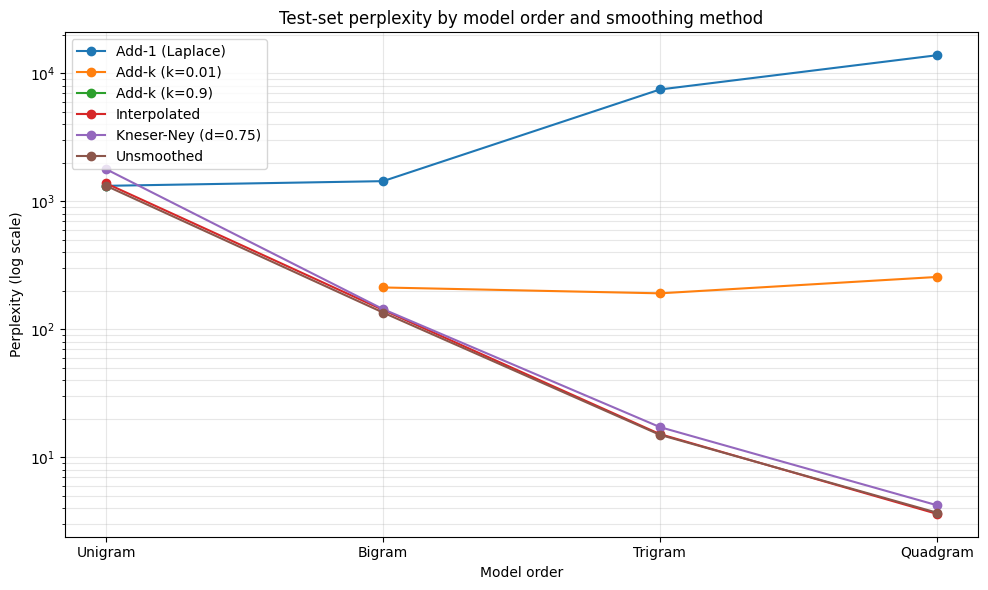

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
for smoothing in pivot.index:
    ax.plot(pivot.columns, pivot.loc[smoothing], marker="o", label=smoothing)
ax.set_yscale("log")
ax.set_xlabel("Model order")
ax.set_ylabel("Perplexity (log scale)")
ax.set_title("Test-set perplexity by model order and smoothing method")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()


## 13. Discussion (fill in with your own numbers)

Things you'll typically observe once this runs on your real corpus:

- **Unsmoothed** perplexity on test is usually the lowest-looking *if* every test n-gram
  happened to be seen in train, but in practice unseen n-grams (probability 0) blow it up
  — that's the whole motivation for smoothing.
- **Add-1** over-smooths for higher orders because `V` is large relative to typical
  context counts, shifting too much mass to unseen events.
- **Add-k** with a tuned small `k` usually beats Add-1, since it discounts less
  aggressively.
- **Interpolation** and **Kneser-Ney** generally give the best (lowest) perplexities,
  especially at higher orders (trigram/quadgram), because they back off gracefully to
  lower-order statistics instead of treating all unseen events identically.
- **Kneser-Ney** typically edges out plain interpolation because it uses continuation
  counts (how many *distinct* contexts a word appears in) rather than raw frequency,
  which better models how "productive" a word is as a novel continuation.

Swap in your real 1,000,000-sentence corpus via `CORPUS_PATH` in Section 1 and re-run
top to bottom to get your actual numbers for the writeup.
